<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_5_seq2seq_atencion.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_5_seq2seq_atencion.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F05_sequences%2Fnotebooks%2Fsesion_05_5_seq2seq_atencion.ipynb)

# SI7011 · Sesión 05 · 5. Seq2seq y atención: ¿qué cabe en un solo vector?
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 5** de las diapositivas. Una red lee una frase en español que contiene una fecha escrita en palabras y escribe la fecha en formato ISO:

> "el contrato se firmó el veintinueve de septiembre de mil novecientos noventa y ocho sin falta" → `1998-09-29`

El codificador lee la frase y termina en un vector $\mathbf h_T$. El decodificador escribe los 10 caracteres de la salida, uno por paso. La pregunta es cuánto de la frase sobrevive en $\mathbf h_T$, y qué cambia cuando el decodificador puede **mirar atrás** a todos los $\mathbf h_t$.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | generar frases con fechas | qué ve la red y qué debe escribir |
| 3 | seq2seq **sin** atención, $d = 128$ | acierto por carácter: ¿qué parte de la fecha falla? |
| 4 | el mismo modelo con $d = 24$ | qué pasa cuando el vector es pequeño |
| 5 | **con** atención, $d = 24$ | el mismo tamaño, otra arquitectura |
| 6 | el mapa de atención $\alpha_{\tau t}$ | la figura de la diapositiva |
| 7 | $d = 48, 64, 96$ sin atención | ¿cuánto debe medir el vector? |

**Datos:** se generan en el notebook; no hay nada que descargar. Corre en CPU en unos 7 minutos (Colab, Kaggle, Lightning o local).

In [1]:
import json, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


## 1. Frases con fechas
Cada ejemplo es una fecha entre 1900 y 2099 con el día y el mes en palabras. El año va en palabras ("mil novecientos noventa y ocho") o en dígitos ("2 0 2 6", un dígito por token), y la fecha aparece dentro de una frase con palabras de relleno antes y después. El relleno hace las frases largas, de 7 a 27 tokens, y obliga a la red a encontrar la fecha.

In [2]:
UNI = ['', 'uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve', 'diez',
       'once', 'doce', 'trece', 'catorce', 'quince', 'dieciséis', 'diecisiete', 'dieciocho', 'diecinueve',
       'veinte', 'veintiuno', 'veintidós', 'veintitrés', 'veinticuatro', 'veinticinco', 'veintiséis',
       'veintisiete', 'veintiocho', 'veintinueve']
DECENAS = {3: 'treinta', 4: 'cuarenta', 5: 'cincuenta', 6: 'sesenta', 7: 'setenta', 8: 'ochenta', 9: 'noventa'}
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre',
         'octubre', 'noviembre', 'diciembre']
DIAS_MES = [31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

def numero(n):                       # 1–99 en palabras
    if n < 30:
        return UNI[n]
    d, u = divmod(n, 10)
    return DECENAS[d] + ('' if u == 0 else ' y ' + UNI[u])

def anio_en_palabras(a):
    if a < 2000:
        return 'mil novecientos' + ('' if a == 1900 else ' ' + numero(a - 1900))
    return 'dos mil' + ('' if a == 2000 else ' ' + numero(a - 2000))

def bisiesto(a):
    return a % 4 == 0 and (a % 100 != 0 or a % 400 == 0)

def fecha(rng):
    a, m = rng.randint(1900, 2099), rng.randint(1, 12)
    d = rng.randint(1, DIAS_MES[m - 1])
    if m == 2 and d == 29 and not bisiesto(a):
        d = 28
    dia = 'primero' if d == 1 else numero(d)
    anio = ' '.join(str(a)) if rng.random() < 0.5 else anio_en_palabras(a)
    return f'{dia} de {MESES[m - 1]} de {anio}'.split(), f'{a:04d}-{m:02d}-{d:02d}'

In [3]:
ANTES = ['la reunión quedó para el', 'nos vemos el', 'el pago vence el', 'según el acta, el evento fue el',
         'llegó a Medellín el', 'el contrato se firmó el', 'recuerda que el examen es el', 'el', 'nació el',
         'la entrega final será el', 'hubo un temblor el', 'el informe dice que el viaje empezó el']
DESPUES = ['', 'en la sala dos', 'a las tres de la tarde', 'sin falta', 'según la secretaría',
           'en el bloque treinta y ocho', 'como estaba previsto', 'y nadie lo olvidó', 'por la mañana',
           'después de varias semanas de espera y muchas llamadas', 'en la sede de la universidad en el centro']

def frase(rng):
    x, y = fecha(rng)
    return rng.choice(ANTES).split() + x + rng.choice(DESPUES).split(), y

train = [frase(random.Random(i)) for i in range(30000)]            # una semilla por ejemplo: reproducible
test = [frase(random.Random(10**6 + i)) for i in range(6000)]
for x, y in train[:4]:
    print(f'{len(x):2d} tokens · {" ".join(x)}  →  {y}')

14 tokens · nació el dos de julio de 1 9 9 8 y nadie lo olvidó  →  1998-07-02
15 tokens · nos vemos el veintiocho de octubre de mil novecientos treinta y cuatro según la secretaría  →  1934-10-28
21 tokens · el pago vence el tres de febrero de 1 9 1 4 en la sede de la universidad en el centro  →  1914-02-03
17 tokens · la entrega final será el dieciocho de octubre de 1 9 6 0 y nadie lo olvidó  →  1960-10-18


La salida tiene siempre 10 caracteres, así que el decodificador da exactamente 10 pasos, $\tau = 1, \dots, 10$. Los pasos 1–4 son el año, 6–7 el mes y 9–10 el día.

Fíjate en el orden: el **día** es lo primero que aparece en la entrada y lo último que se escribe en la salida.

## 2. Vocabularios y tensores
Entrada: un vocabulario de palabras construido con el conjunto de **entrenamiento** (las palabras nuevas irían a `[UNK]`; aquí no aparece ninguna). Salida: 11 caracteres más `[START]`, el token con el que arranca el decodificador.

In [4]:
VOCAB = ['[PAD]', '[UNK]'] + sorted({w for x, _ in train for w in x})
W2I = {w: i for i, w in enumerate(VOCAB)}
SALIDA = ['[START]'] + list('0123456789-')
C2I = {c: i for i, c in enumerate(SALIDA)}

def tensores(pares):
    T = max(len(x) for x, _ in pares)
    X = torch.zeros(len(pares), T, dtype=torch.long)                    # 0 = [PAD]
    for i, (x, _) in enumerate(pares):
        X[i, :len(x)] = torch.tensor([W2I.get(w, 1) for w in x])
    Y = torch.tensor([[C2I[c] for c in y] for _, y in pares])           # (B, 10)
    return X, Y

print(len(VOCAB), 'palabras ·', len(SALIDA), 'símbolos de salida')
X, Y = tensores(train[:3]); X.shape, Y.shape

124 palabras · 12 símbolos de salida


(torch.Size([3, 21]), torch.Size([3, 10]))

## Herramientas: el modelo, el loop y la evaluación
Un solo modelo con un interruptor `atencion`:

- **codificador:** embeddings y una GRU que lee la frase, $\mathbf h_t$ para $t = 1, \dots, T$;
- **decodificador:** una `GRUCell` que arranca en $\mathbf s_0 = \mathbf h_T$ y recibe el carácter anterior $y_{\tau-1}$;
- **con atención** (Bahdanau, 2015): en cada paso puntúa todos los $\mathbf h_t$ con el estado anterior $\mathbf s_{\tau-1}$, normaliza con softmax y promedia:

$$
\alpha_{\tau t} = \operatorname{softmax}_t\big(\mathbf v^\top \tanh(W_s \mathbf s_{\tau-1} + W_h \mathbf h_t)\big),
\qquad
\mathbf a_\tau = \sum_t \alpha_{\tau t}\,\mathbf h_t
$$

El contexto $\mathbf a_\tau$ entra al decodificador junto con $y_{\tau-1}$. Sin atención, todo lo que el decodificador sabe de la frase está en $\mathbf s_0 = \mathbf h_T$.

In [5]:
class Seq2Seq(nn.Module):
    def __init__(self, atencion, d=64, d_e=32):
        super().__init__()
        self.atencion = atencion
        self.emb_x = nn.Embedding(len(VOCAB), d_e, padding_idx=0)       # e_w de la entrada
        self.encoder = nn.GRU(d_e, d, batch_first=True)                  # h_1, …, h_T
        self.emb_y = nn.Embedding(len(SALIDA), d_e)                      # el carácter anterior y_{τ-1}
        self.decoder = nn.GRUCell(d_e + (d if atencion else 0), d)       # s_τ
        self.W_s = nn.Linear(d, d, bias=False)                           # puntaje aditivo
        self.W_h = nn.Linear(d, d)
        self.v = nn.Linear(d, 1, bias=False)
        self.salida = nn.Linear(2 * d if atencion else d, len(SALIDA))

    def codificar(self, X):
        mascara = X != 0                                                 # False en el padding
        H, _ = self.encoder(self.emb_x(X))                               # (B, T, d)
        largo = mascara.sum(1)
        h_T = H[torch.arange(len(X)), largo - 1]                         # el último paso real, no el padding
        return H, h_T, mascara

    def paso(self, y_prev, s, H, mascara):
        e = self.emb_y(y_prev)
        if not self.atencion:
            s = self.decoder(e, s)
            return self.salida(s), s, None
        puntaje = self.v(torch.tanh(self.W_s(s)[:, None] + self.W_h(H))).squeeze(-1)    # score(s_{τ-1}, h_t)
        alpha = torch.softmax(puntaje.masked_fill(~mascara, -1e9), dim=1)              # α_{τt}: el padding pesa 0
        a = (alpha[..., None] * H).sum(1)                                              # a_τ = Σ_t α_{τt} h_t
        s = self.decoder(torch.cat([e, a], -1), s)
        return self.salida(torch.cat([s, a], -1)), s, alpha

    def forward(self, X, Y):                                             # teacher forcing
        H, s, mascara = self.codificar(X)                                # s_0 = h_T
        y_prev = torch.zeros(len(X), dtype=torch.long)                   # [START]
        logits = []
        for tau in range(Y.shape[1]):
            o, s, _ = self.paso(y_prev, s, H, mascara)
            logits.append(o)
            y_prev = Y[:, tau]                                           # el carácter verdadero, no el predicho
        return torch.stack(logits, 1)

    @torch.no_grad()
    def decodificar(self, X):                                            # inferencia: greedy, su propia salida
        H, s, mascara = self.codificar(X)
        y_prev = torch.zeros(len(X), dtype=torch.long)
        salidas, alphas = [], []
        for tau in range(10):
            o, s, alpha = self.paso(y_prev, s, H, mascara)
            y_prev = o.argmax(-1)
            salidas.append(y_prev)
            alphas.append(alpha)
        return torch.stack(salidas, 1), (torch.stack(alphas, 1) if self.atencion else None)

In [6]:
def entrenar(modelo, epocas=10, lote=128, lr=3e-3):
    opt = torch.optim.Adam(modelo.parameters(), lr)
    datos, t0 = list(train), time.time()
    for ep in range(epocas):
        modelo.train()
        random.Random(ep).shuffle(datos)
        for i in range(0, len(datos), lote):
            X, Y = tensores(datos[i:i + lote])
            # L = Σ_τ −log p(y_τ | y_<τ, x): la entropía cruzada de la sesión 01, sumada sobre los 10 pasos
            loss = nn.functional.cross_entropy(modelo(X, Y).transpose(1, 2), Y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)          # clipping, como en la Parte 2
            opt.step()
    print(f'pérdida final {loss.item():.4f} · {time.time() - t0:.0f} s · {sum(p.numel() for p in modelo.parameters()):,} parámetros')
    return modelo

def evaluar(modelo, pares=test):
    """Acierto exacto (las 10 posiciones bien) y acierto por posición, decodificando sin teacher forcing."""
    modelo.eval()
    X, Y = tensores(pares)
    P, _ = modelo.decodificar(X)
    return (P == Y).all(1).float().mean().item(), (P == Y).float().mean(0).numpy()

POSICIONES = list('AAAA-MM-DD')                                         # año, mes, día
resultados = {}
def anotar(nombre, modelo):
    exacto, por_pos = evaluar(modelo)
    resultados[nombre] = {'exacto': exacto, 'por_posicion': por_pos.tolist(),
                          'parametros': sum(p.numel() for p in modelo.parameters())}
    print(f'{nombre}: acierto exacto {exacto:.3f}')
    print('  por posición', ' '.join(f'{c}:{v:.2f}' for c, v in zip(POSICIONES, por_pos)))

## 3. Seq2seq sin atención, $d = 128$
Todo pasa por $\mathbf h_T \in \mathbb R^{128}$. Antes de correr: ¿qué parte de la fecha crees que falla más, el año, el mes o el día?

In [7]:
torch.manual_seed(0)
sin_128 = entrenar(Seq2Seq(atencion=False, d=128))
anotar('sin atención, d=128', sin_128)

pérdida final 0.0231 · 53 s · 163,340 parámetros


sin atención, d=128: acierto exacto 0.928
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:0.98 -:1.00 D:0.99 D:0.94


Con un vector grande, casi todo bien. Si quedan errores, mira **dónde**: en los dígitos del día, la información que el codificador leyó **primero** y la que lleva más pasos dentro de $\mathbf h_t$ cuando la lectura termina (Parte 2: lo que está lejos se desvanece).

## 4. El mismo modelo, con un vector más pequeño: $d = 24$
Un solo cambio: $d = 128 \to 24$. La frase, el entrenamiento y el número de épocas son los mismos.

In [8]:
torch.manual_seed(0)
sin_24 = entrenar(Seq2Seq(atencion=False, d=24))
anotar('sin atención, d=24', sin_24)

pérdida final 0.5809 · 23 s · 14,204 parámetros
sin atención, d=24: acierto exacto 0.004
  por posición A:1.00 A:1.00 A:0.98 A:0.95 -:1.00 M:0.76 M:0.15 -:1.00 D:0.32 D:0.09


El modelo casi nunca acierta la fecha completa. El año (lo último que leyó) sigue saliendo bien; el mes y sobre todo el día se pierden. Con 24 números, $\mathbf h_T$ no alcanza para llevar la fecha **y** sobrevivir al relleno que viene después.

## 5. Con atención, el mismo $d = 24$
Otro solo cambio: `atencion=True`. El decodificador ya no depende solo de $\mathbf h_T$: en cada paso lee directamente los $\mathbf h_t$ que necesita.

In [9]:
torch.manual_seed(0)
con_24 = entrenar(Seq2Seq(atencion=True, d=24))
anotar('con atención, d=24', con_24)

pérdida final 0.0003 · 42 s · 16,220 parámetros
con atención, d=24: acierto exacto 1.000
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


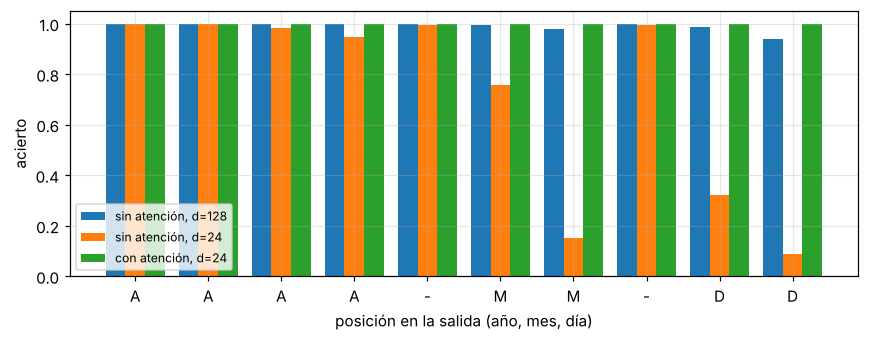

In [10]:
nombres = ['sin atención, d=128', 'sin atención, d=24', 'con atención, d=24']
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, n in enumerate(nombres):
    ax.bar(np.arange(10) + (k - 1) * 0.27, resultados[n]['por_posicion'], width=0.27, label=n)
ax.set_xticks(range(10), POSICIONES); ax.set_ylim(0, 1.05)
ax.set_xlabel('posición en la salida (año, mes, día)'); ax.set_ylabel('acierto')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

## 6. Dónde mira el decodificador
Tres frases fijas: una corta con "primero", una con el año en palabras y una con relleno después de la fecha. Cada fila del mapa es un carácter de la salida y cada columna una palabra de la entrada; el color es $\alpha_{\tau t}$, y cada fila suma 1.

2026-05-01 ← nos vemos el primero de mayo de 2 0 2 6
1998-09-29 ← el contrato se firmó el veintinueve de septiembre de mil novecientos noventa y ocho sin falta
2026-10-19 ← el diecinueve de octubre de 2 0 2 6 en la sala dos


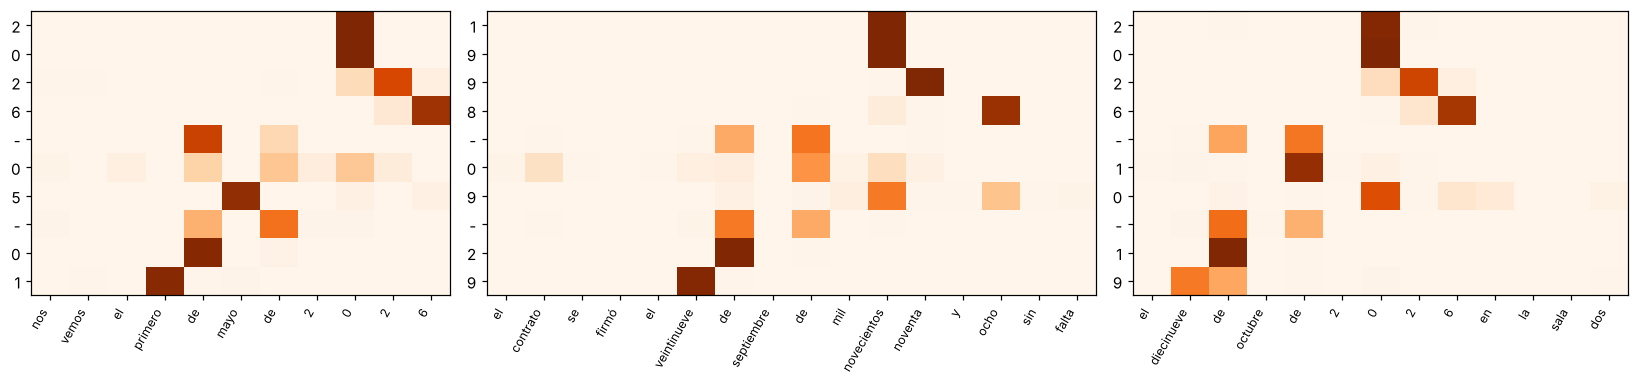

In [11]:
EJEMPLOS = ['nos vemos el primero de mayo de 2 0 2 6',
            'el contrato se firmó el veintinueve de septiembre de mil novecientos noventa y ocho sin falta',
            'el diecinueve de octubre de 2 0 2 6 en la sala dos']
mapas, salidas = [], []
for frase_txt in EJEMPLOS:
    X, _ = tensores([(frase_txt.split(), '0000-00-00')])
    P, A = con_24.decodificar(X)                                         # A: (1, 10, T)
    salidas.append(''.join(SALIDA[i] for i in P[0]))
    mapas.append(A[0].numpy())
    print(salidas[-1], '←', frase_txt)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={'width_ratios': [len(e.split()) for e in EJEMPLOS]})
for ax, m, e, s in zip(axes, mapas, EJEMPLOS, salidas):
    ax.imshow(m, cmap='Oranges', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(e.split())), e.split(), rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(10), list(s)); ax.grid(False)
plt.tight_layout(); plt.show()

Los dígitos del año miran el año y los del mes miran el mes; el relleno recibe casi nada. Nadie le dijo a la red qué palabra corresponde a qué carácter: el alineamiento sale solo de la pérdida de la salida.

Mira el **día**: a menudo la atención no cae en la palabra del día sino en el "de" que viene justo después. No es un error. La atención elige **estados** $\mathbf h_t$, no palabras, y con una GRU que lee de izquierda a derecha el estado en ese "de" ya contiene el día que acaba de leer. Por eso un mapa de atención es una pista, no una explicación (sesión 03).

In [12]:
# Lo que leen la figura S05-F09 y la animación S05-A03 (make_s05_figuras_notebooks.py, escenas_s05.py)
np.savez('atencion_fechas.npz', ejemplos=np.array(EJEMPLOS), salidas=np.array(salidas),
         **{f'alpha_{k}': m for k, m in enumerate(mapas)})

## 7. ¿Cuánto debe medir el vector?
Sin atención, con $d = 48$, $64$ y $96$, para completar la curva entre los puntos de las secciones 4 ($d = 24$) y 3 ($d = 128$). Unos 2 minutos.

In [13]:
for d in (48, 64, 96):
    torch.manual_seed(0)
    anotar(f'sin atención, d={d}', entrenar(Seq2Seq(atencion=False, d=d)))

pérdida final 0.3207 · 31 s · 33,260 parámetros
sin atención, d=48: acierto exacto 0.066
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:0.95 -:1.00 D:0.58 D:0.11


pérdida final 0.1914 · 32 s · 51,084 parámetros
sin atención, d=64: acierto exacto 0.229
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:0.94 D:0.23


pérdida final 0.0007 · 39 s · 99,020 parámetros


sin atención, d=96: acierto exacto 1.000
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


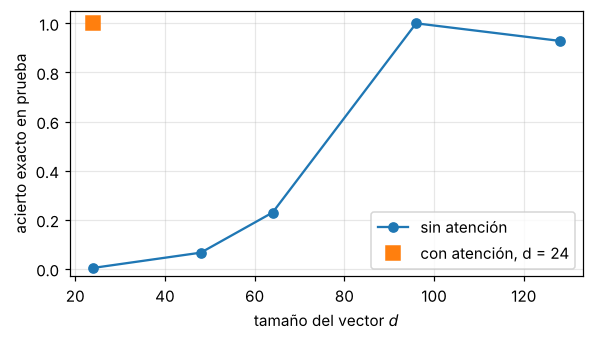

In [14]:
ds = [24, 48, 64, 96, 128]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(ds, [resultados[f'sin atención, d={d}']['exacto'] for d in ds], 'o-', label='sin atención')
ax.plot([24], [resultados['con atención, d=24']['exacto']], 's', ms=9, label='con atención, d = 24')
ax.set_xlabel('tamaño del vector $d$'); ax.set_ylabel('acierto exacto en prueba'); ax.set_ylim(-0.03, 1.05)
ax.legend(); plt.tight_layout(); plt.show()
json.dump(resultados, open('resultados_seq2seq.json', 'w'), ensure_ascii=False, indent=1)

Sin atención, hace falta un vector de unos 100 números; con atención, $d = 24$ basta. El cuello de botella no es la arquitectura recurrente: es pedirle a **un** vector que lleve toda la frase.

Entre $d = 48$ y $d = 96$ el modelo sin atención está en el borde: con otra semilla el mismo $d$ puede dar 5 % o 50 %. Si tu curva no se parece a la de tu compañero en esa zona, no hay un error: es la señal de que una sola corrida no basta para decidir (sesión 02). Los extremos, $d = 24$ sin atención y con atención, dan lo mismo con cualquier semilla.

En esta tarea el efecto no depende de la longitud de la frase (pruébalo en *Tu turno*): la fecha es poca información y el relleno no trae nada que guardar. En traducción, donde cada palabra de la entrada importa, la calidad sin atención sí cae con la longitud (Cho et al., 2014).

## Tu turno · 10 minutos
1. Agrupa la prueba por longitud de la frase (`len(x)`) y calcula el acierto exacto de `sin_128` en cada grupo. ¿Cae con la longitud?
2. Repite la sección 7 con `torch.manual_seed(1)`. ¿Qué puntos de la curva cambian?
3. Entrena solo con frases de 19 tokens o menos y prueba con las de 20 o más, con y sin atención. ¿Cuál extrapola mejor a frases más largas que las vistas? Ojo: eso es otra pregunta distinta a la del cuello de botella.
4. Cambia `nn.GRU` por `nn.LSTM` en el codificador sin atención con $d = 24$ (devuelve `(h, c)`; el decodificador puede arrancar de `h`). ¿Cambia el resultado de la sección 4?

**Para pensar.** Con atención, el decodificador lee todos los $\mathbf h_t$, pero el codificador sigue siendo recurrente: el paso $t$ espera al paso $t-1$. ¿Qué pasaría si cada palabra pudiera mirar directamente a todas las demás desde el principio? (sesión 06)

In [15]:
# Tu turno

### Referencias
- Sutskever, Vinyals y Le (2014), *Sequence to Sequence Learning with Neural Networks*, NeurIPS.
- Cho, van Merriënboer, Bahdanau y Bengio (2014), *On the Properties of Neural Machine Translation: Encoder–Decoder Approaches*, SSST-8.
- Bahdanau, Cho y Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR.
- Luong, Pham y Manning (2015), *Effective Approaches to Attention-based Neural Machine Translation*, EMNLP.